# Leading against lagging indicators: which number warns while a team can still act, and which only confirms?

**Week 4, Monday, chapter 3 of 11, concept chapter 3 of 6.** The topic, in the curriculum's words: *Leading against lagging indicators*. Every number in this notebook is invented for the chapter and small enough to count by hand. It is read from a table the day's generator wrote to `data/`, and the code only confirms the count.

**Who needs the answer.** The captain of a side chasing a T20 total (invented), who can still change the batting order after over 10 and cannot change the scoreboard after over 20. After the break, Uber's city team, which could have seen its scheme drift in the first week.

**The questions on the way.**

1. What does the chase's table hold?
2. When does the runs an over needed first reach 10?
3. When does the result arrive, and what is it?
4. Which number is read beside the warning one?
5. Can the warning be written as a rule?
6. What did the chase need after over 15, in your turn?

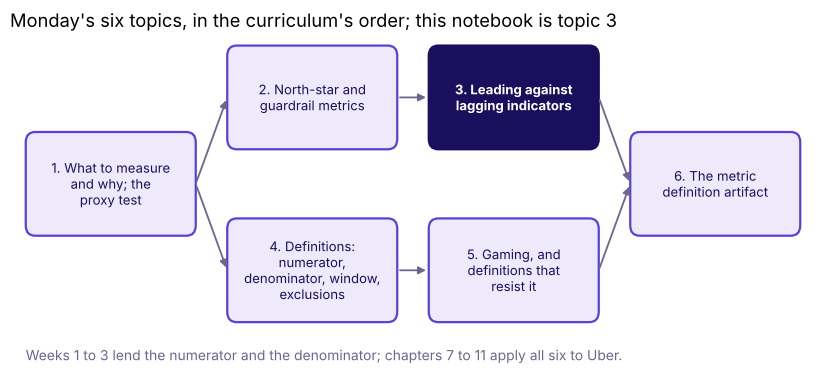

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print("PASS" if ok else "FAIL", name)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, VIOLET, ROSE, LAV, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#D9A7FF", "#6B6690"

from matplotlib.patches import FancyBboxPatch, Patch

TOPICS = ["1. What to measure\nand why; the\nproxy test", "2. North-star and\nguardrail metrics",
          "3. Leading against\nlagging indicators", "4. Definitions:\nnumerator,\ndenominator, window,\nexclusions",
          "5. Gaming, and\ndefinitions that\nresist it", "6. The metric\ndefinition artifact"]
PLACE = [(1.6, 2.25), (4.8, 3.5), (8.0, 3.5), (4.8, 1.0), (8.0, 1.0), (11.2, 2.25)]
LINKS = [(0, 1), (1, 2), (0, 3), (3, 4), (2, 5), (4, 5)]


def topic_map(lit):
    """Monday's six topics in the curriculum's order, joined as the deck's concept map joins them."""
    fig, ax = plt.subplots(figsize=(10.4, 4.4))
    w, h = 2.7, 1.5
    for a, b in LINKS:
        (xa, ya), (xb, yb) = PLACE[a], PLACE[b]
        ax.annotate("", xy=(xb - w / 2, yb), xytext=(xa + w / 2, ya),
                    arrowprops={"arrowstyle": "-|>", "color": MUTED, "lw": 1.3})
    for i, ((x, y), label) in enumerate(zip(PLACE, TOPICS), start=1):
        on = i == lit
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.15",
                                    fc=INK if on else "#EEEAFB", ec=INK if on else VIOLET, lw=1.6))
        ax.text(x, y, label, ha="center", va="center", fontsize=9.5, color="white" if on else INK,
                fontweight="bold" if on else "normal")
    ax.text(0.25, -0.3, "Weeks 1 to 3 lend the numerator and the denominator; chapters 7 to 11 apply all six to Uber.",
            fontsize=10, color=MUTED)
    ax.set_xlim(0, 12.8)
    ax.set_ylim(-0.5, 4.4)
    ax.axis("off")
    ax.set_title(f"Monday's six topics, in the curriculum's order; this notebook is topic {lit}", loc="left")
    plt.show()

topic_map(3)

## What does the chase's table hold?

The other side made 159 in its 20 overs (invented), so the chase needs 160 to win. The table
holds the runs made in each of the 20 overs and the wickets lost in each; a side has 10 wickets.
This cell loads the 20 overs and prints every row.

In [2]:
overs = pd.read_csv("../data/C2_W04_D01_chase_overs_STUDENT.csv")
print("A T20 chase of 160, every ball of it invented for this chapter:")
print(overs.to_string(index=False))
check("20 overs, 147 runs and 7 wickets in all",
      len(overs) == 20 and overs["runs"].sum() == 147 and overs["wickets_lost"].sum() == 7)

A T20 chase of 160, every ball of it invented for this chapter:
 over  runs  wickets_lost
    1     6             0
    2     6             0
    3     6             1
    4     6             0
    5     6             0
    6     6             0
    7     6             1
    8     6             0
    9     6             0
   10     6             1
   11     7             0
   12     8             0
   13     9             1
   14    10             0
   15     8             0
   16     9             1
   17    10             0
   18    11             1
   19     9             1
   20     6             0
PASS 20 overs, 147 runs and 7 wickets in all


## When does the chase first need 10 an over?

**Predict before you run.** When does the runs an over needed first reach 10?

a) After over 5, a third of the way in.
b) After over 10, halfway, at 60 for 3.
c) After over 15, five overs from the end.
d) Only at the end, when the last ball is bowled.

The next cell counts by hand for the start, over 5 and over 10, one line per step: runs still
needed over overs left. Then it counts every over by code and checks that the two agree. Over 20
leaves no overs to divide by, so the column stops at over 19.

In [3]:
# By hand, one line per step: runs still needed / overs left
hand_start = 160 / 20                # before a ball is bowled: 8.0 an over
hand_after_5 = (160 - 30) / 15       # five overs of 6 make 30: 8.7 an over
hand_after_10 = (160 - 60) / 10      # ten overs of 6 make 60: 10.0 an over

# By code, every over
overs["so_far"] = overs["runs"].cumsum()
overs["in_hand"] = 10 - overs["wickets_lost"].cumsum()
play = overs[overs["over"] < 20].copy()
play["needed_an_over"] = (160 - play["so_far"]) / (20 - play["over"])
print(play[["over", "so_far", "in_hand", "needed_an_over"]].round(1).to_string(index=False))
first_ten = int(play.loc[play["needed_an_over"] >= 10, "over"].iloc[0])
print("the runs an over needed first reaches 10 after over", first_ten)
check("hand and code agree: 8.7 an over after over 5 and 10.0 after over 10",
      round(play.loc[play["over"] == 5, "needed_an_over"].iloc[0], 1) == round(hand_after_5, 1)
      and play.loc[play["over"] == 10, "needed_an_over"].iloc[0] == hand_after_10)
check("the rate needed first reaches 10 after over 10", first_ten == 10)

 over  so_far  in_hand  needed_an_over
    1       6       10             8.1
    2      12       10             8.2
    3      18        9             8.4
    4      24        9             8.5
    5      30        9             8.7
    6      36        9             8.9
    7      42        8             9.1
    8      48        8             9.3
    9      54        8             9.6
   10      60        7            10.0
   11      67        7            10.3
   12      75        7            10.6
   13      84        6            10.9
   14      94        6            11.0
   15     102        6            11.6
   16     111        5            12.2
   17     121        5            13.0
   18     132        4            14.0
   19     141        3            19.0
the runs an over needed first reaches 10 after over 10
PASS hand and code agree: 8.7 an over after over 5 and 10.0 after over 10
PASS the rate needed first reaches 10 after over 10


**What happened.** The answer is b. Six an over for ten overs made 60, so 100 were still needed
from 10 overs, 10.0 an over, against 8.0 before a ball was bowled. The plausible wrong answer is
d: a chase feels lost only when the last over ends.

## When does the result arrive?

This cell draws the runs an over needed after every over, with the level of 10 dotted and over
20, where the scoreboard confirms the result, dashed.

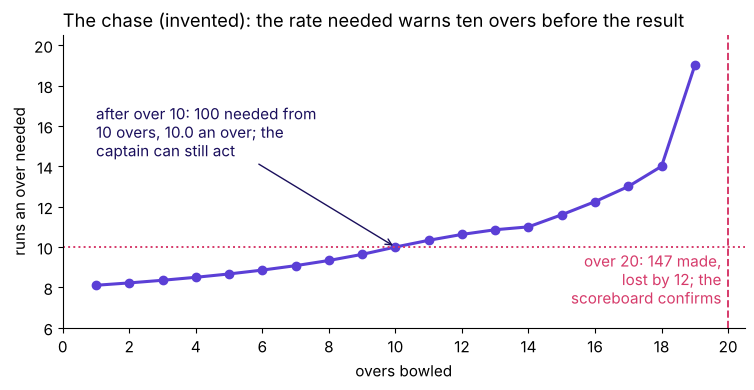

In [4]:
fig, ax = plt.subplots(figsize=(8.8, 3.8))
ax.plot(play["over"], play["needed_an_over"], marker="o", color=VIOLET, lw=2.2, label="runs an over needed to win")
ax.axhline(10, color=ROSE, linestyle=":", lw=1.4)
ax.axvline(20, color=ROSE, linestyle="--", lw=1.4)
ax.annotate("after over 10: 100 needed from\n10 overs, 10.0 an over; the\ncaptain can still act", xy=(10, 10.0),
            xytext=(1, 14.5), arrowprops={"arrowstyle": "->", "color": INK}, color=INK)
ax.text(19.8, 7.2, "over 20: 147 made,\nlost by 12; the\nscoreboard confirms", ha="right", color=ROSE)
ax.set_xticks(range(0, 21, 2))
ax.set_xlim(0, 20.5)
ax.set_ylim(6, 20.5)
ax.set_xlabel("overs bowled")
ax.set_ylabel("runs an over needed")
ax.set_title("The chase (invented): the rate needed warns ten overs before the result", loc="left")
plt.show()

The runs an over needed climbed past 10 at over 10, while the captain could still promote a
hitter; the margin arrived at over 20. Named last: a **leading indicator** moves before the north
star, while the team can still act on it, and a **lagging indicator** confirms the north star
after the result is fixed. Leading and lagging say when a number moves, which is a separate
question from the job it does, so one number can be a guardrail and a leading number at once.

## Which number is read beside the warning one?

A leading number is read beside a guardrail: 10 an over with 7 wickets in hand is a different
chase from 10 an over with 2. This cell draws the runs made against the 8 an over that 160 asked
for, and the wickets in hand over by over, then reads the result.

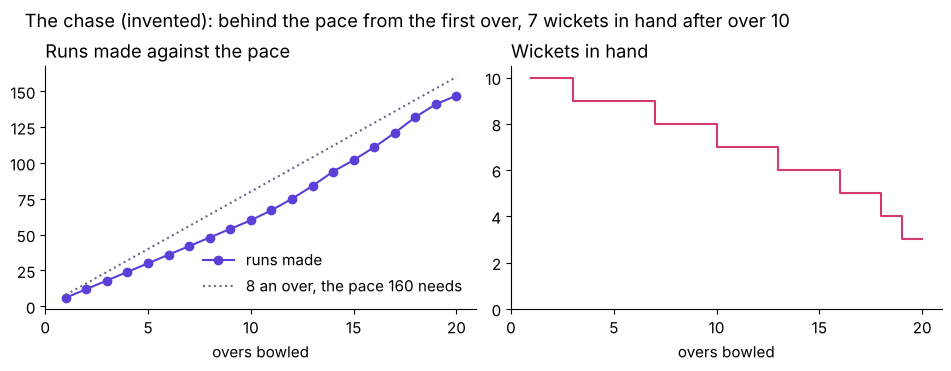

after over 20: 147 made against 159, lost by 12 runs
PASS 7 wickets in hand after over 10
PASS the result, 147 made and lost by 12, arrives only after over 20


In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.4, 3.6), layout="constrained")
a1.plot(overs["over"], overs["so_far"], marker="o", color=VIOLET, label="runs made")
a1.plot(overs["over"], overs["over"] * 8, linestyle=":", color=MUTED, label="8 an over, the pace 160 needs")
a1.set_xlabel("overs bowled")
a1.legend(frameon=False, loc="lower right")
a1.set_title("Runs made against the pace", loc="left")
a2.step(overs["over"], overs["in_hand"], where="post", color=ROSE)
a2.set_ylim(0, 10.5)
for a in (a1, a2):
    a.set_xticks(range(0, 21, 5))
a2.set_xlabel("overs bowled")
a2.set_title("Wickets in hand", loc="left")
fig.suptitle("The chase (invented): behind the pace from the first over, 7 wickets in hand after over 10",
             x=0.02, ha="left")
plt.show()
final, margin = overs["so_far"].iloc[-1], 159 - overs["so_far"].iloc[-1]
print(f"after over 20: {final} made against 159, lost by {margin} runs")
check("7 wickets in hand after over 10", overs.loc[overs["over"] == 10, "in_hand"].iloc[0] == 7)
check("the result, 147 made and lost by 12, arrives only after over 20", (final, margin) == (147, 12))

## Can the warning be written as a rule?

This cell writes the rule as a short function: the first point at which a number reaches a level
the team has set in advance. On the chase it finds the over the runs an over needed reached 10,
and the overs between that warning and the result.

In [6]:
def first_crossing(values, level):
    """The first label at which a series reaches a level set in advance, or None if it never does."""
    hit = values >= level
    return hit.idxmax() if hit.any() else None

needed = play.set_index("over")["needed_an_over"]
warned = first_crossing(needed, 10)
print(f"the rate needed warned after over {warned}; the result arrived after over 20, {20 - warned} overs later")
check("the leading number warned ten overs before the lagging one confirmed", 20 - warned == 10)

the rate needed warned after over 10; the result arrived after over 20, 10 overs later
PASS the leading number warned ten overs before the lagging one confirmed


### Your turn: what did the chase need after over 15?

In the empty cell below, fill the two blanks and run it:

```python
after_15 = overs[overs["over"] == 15].iloc[0]
needed_after_15 = (160 - after_15[____]) / (20 - 15)   # runs still needed over overs left
in_hand_after_15 = after_15[____]                      # wickets still in hand
```

The check under it compares both with the reference, and shows the reference only once your
numbers exist. Then say whether a captain would still change the plan at that point, and which
of the two numbers told you.

In [7]:
mine = (globals().get("needed_after_15"), globals().get("in_hand_after_15"))
if None in mine:
    print("Store needed_after_15 and in_hand_after_15 in the empty cell above, then run this cell again.")
else:
    ref = overs[overs["over"] == 15].iloc[0]
    want = ((160 - ref["so_far"]) / 5, ref["in_hand"])
    print(f"reference: {want[0]:.1f} an over with {want[1]} wickets in hand; yours: {mine[0]:.1f} with {mine[1]}")
    print("matches" if abs(mine[0] - want[0]) <= 0.05 and mine[1] == want[1] else "not yet: which column is the running total?")

Store needed_after_15 and in_hand_after_15 in the empty cell above, then run this cell again.


## What does chapter 3 leave?

1. The chase (invented): 6 an over for ten overs, then 7 to 11, ending on 147 for 7 against 160.
2. The runs an over needed first reached 10 after over 10, at 60 for 3.
3. The result, 147 against 159 and lost by 12, arrived only after over 20, ten overs later.
4. Wickets in hand, 7 after over 10, are the guardrail the warning number is read with.
5. `first_crossing(values, level)` finds the point a warning number reaches the level set in
   advance.

**The rules.**

- A leading number moves before the north star, while the team can still act on it.
- A lagging number confirms the north star after the result is fixed.
- Read a leading number beside its guardrail: 10 an over with 7 wickets in hand is a different
  chase from 10 an over with 2.
- A dashboard of lagging numbers alone lets a drift run for weeks before anyone sees it.

**In the interview.** [F] North-star against guardrail, with one example pair, and the leading
input that moves first.

**Where it goes next.** Notebook 04 writes down the four lines that make any of these numbers
computable. After the break, `C2_W04_D01_09_north_star_guardrails_cost_STUDENT.ipynb` asks which
of Uber's numbers moved first, and finds the share of offers accepted settling in the scheme's
first week while bookings per online hour kept falling for two more.